# Student Final Exam Score Prediction using Linear Regression

## Project Overview

This project aims to develop a Machine Learning model that predicts a student's **Final Exam Score** based on various academic, personal, and lifestyle factors. The objective is to understand how different attributes influence academic performance and to build a predictive model using **Linear Regression**.

---

# Problem Statement

Develop a Machine Learning model to predict a student's **Final Exam Score** using features such as study time, attendance, sleep hours, parental education, internet access, extracurricular activities, part-time job status, and previous academic performance.

---

# Objective

* Predict the final exam score of students.
* Analyze the factors affecting academic performance.
* Apply data preprocessing techniques.
* Train and evaluate a Linear Regression model.
* Understand the complete Machine Learning workflow.

---

# Dataset Description

The dataset contains information about students' academic and personal characteristics.

| Feature                    | Description                                 |
| -------------------------- | ------------------------------------------- |
| student_id                 | Unique identifier for each student          |
| gender                     | Gender of the student                       |
| study_time_hours           | Average daily study time (hours)            |
| attendance_percent         | Attendance percentage                       |
| sleep_hours                | Average daily sleep duration                |
| parental_education         | Highest education level of parent           |
| internet_access            | Internet availability (Yes/No)              |
| extracurricular_activities | Participation in extracurricular activities |
| part_time_job              | Whether the student has a part-time job     |
| previous_grade             | Previous exam score                         |
| final_exam_score           | **Target Variable**                         |
| final_grade                | Final letter grade                          |

---

# Target Variable

**final_exam_score**

The model predicts the student's final examination score.

---

# Input Features

* gender
* study_time_hours
* attendance_percent
* sleep_hours
* parental_education
* internet_access
* extracurricular_activities
* part_time_job
* previous_grade

---

# Machine Learning Algorithm

Primary Algorithm:

* **Linear Regression**

Optional Algorithms:

* Ridge Regression
* Lasso Regression

---

# Data Preprocessing

The following preprocessing steps are performed before training the model:

* Remove unnecessary columns (`student_id`)
* Handle missing values
* Encode categorical variables
* Split features and target
* Train-Test Split
* Feature scaling (if required)

# Expected Outcome

The trained model should accurately estimate a student's final exam score using academic and personal attributes. The prediction can help educators identify students who may require additional academic support.

---

# Applications

* Student performance prediction
* Early academic intervention
* Educational analytics
* Learning performance assessment
* Decision support for educators

---

# Technologies Used

* Python
* Pandas
* NumPy




In [ ]:
import pandas  as pd
df = pd.read_csv('student_performance_dataset.csv')
df.head(5)

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,7.3,80.8,8.1,Bachelors,Yes,No,No,51.9,68.0,D
1,2,Female,5.8,79.2,7.8,Masters,Yes,Yes,Yes,59.3,67.6,D
2,3,Male,3.8,61.0,6.9,NaN,Yes,No,No,91.6,54.7,F
3,4,Male,8.3,73.6,8.8,Bachelors,Yes,Yes,No,88.3,83.0,B
4,5,Male,7.2,75.2,5.0,Masters,Yes,Yes,Yes,67.5,63.5,D


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [ ]:
# Make a copy to avoid modifying the original DataFrame directly
df_processed = df.copy()
df.head()
df.columns


Index(['student_id', 'gender', 'study_time_hours', 'attendance_percent',
       'sleep_hours', 'parental_education', 'internet_access',
       'extracurricular_activities', 'part_time_job', 'previous_grade',
       'final_exam_score', 'final_grade'],
      dtype='object')

#### T1: Building programs to work with the data pre-processing in python

In this practical, I am performing data preprocessing using Python.

First, I load the student performance dataset using Pandas.

Then, I check for missing values and handle them using appropriate techniques.

I remove unnecessary columns, encode categorical variables into numerical values, and separate the independent and dependent variables.

Finally, I split the dataset into 80% training data and 20% testing data.

This prepares the dataset for machine learning algorithms.

In [ ]:
# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Remove unnecessary columns
df = df.drop(["student_id", "final_grade"], axis=1)

# 3. Handle missing values
df["parental_education"] = df["parental_education"].fillna(
    df["parental_education"].mode()[0]
)

# 4. Convert categorical columns into numbers
le = LabelEncoder()

df["gender"] = le.fit_transform(df["gender"])
df["internet_access"] = le.fit_transform(df["internet_access"])
df["extracurricular_activities"] = le.fit_transform(df["extracurricular_activities"])
df["part_time_job"] = le.fit_transform(df["part_time_job"])
df["parental_education"] = le.fit_transform(df["parental_education"])

# 5. Separate features and target
X = df.drop("final_exam_score", axis=1)
y = df["final_exam_score"]

print("\nData preprocessing completed successfully!")

Missing values:
student_id                     0
gender                         0
study_time_hours               0
attendance_percent             0
sleep_hours                    0
parental_education            92
internet_access                0
extracurricular_activities     0
part_time_job                  0
previous_grade                 0
final_exam_score               0
final_grade                    0
dtype: int64

Data preprocessing completed successfully!


*Split for Train and Test*

In [ ]:
from sklearn.model_selection import train_test_split


# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Scale numerical features
scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)
# X_test = scaler.transform(X_test) # logical erroe due to labelencoder

print("Dataset split into training and testing sets.")

# Display the shapes of the resulting sets
print("\nTraining feature shape (X_train):", X_train.shape)
print("Testing feature shape (X_test):", X_test.shape)
print("Training target shape (y_train):", y_train.shape)
print("Testing target shape (y_test):", y_test.shape)

Dataset split into training and testing sets.

Training feature shape (X_train): (800, 9)
Testing feature shape (X_test): (200, 9)
Training target shape (y_train): (800,)
Testing target shape (y_test): (200,)


In [ ]:
print(X.select_dtypes(include="object").columns)
print(X.dtypes) # anytext is pending or  not

Index([], dtype='object')
gender                          int64
study_time_hours              float64
attendance_percent            float64
sleep_hours                   float64
parental_education              int64
internet_access                 int64
extracurricular_activities      int64
part_time_job                   int64
previous_grade                float64
dtype: object


## T2: Building programs to work with linear regression in python

In this practical, I am implementing Linear Regression using Scikit-learn.

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

First, I initialize the Linear Regression model using LinearRegression().

Then, I train the model using the fit() function.

The model learns the relationship between input features and the target variable.

Here, my objective is to predict students' final examination scores.

In [ ]:
from sklearn.linear_model import LinearRegression

# print("--- Training Linear Regression Model ---")

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


##  T3: Building programs to work with cross validation in Python

In this practical, I am implementing 5-Fold Cross Validation.

Cross Validation is used to evaluate the model on different subsets of the dataset.

First, I initialize the KFold object with five splits.

Then, I use cross_val_score() to evaluate the Linear Regression model.

The model is trained and tested five times using different subsets.

Finally, I calculate the mean score and standard deviation to understand the consistency of model performance.

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Define 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Perform Cross Validation
scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

# Display results
print("Cross Validation Scores:", scores)
print("Mean R² Score:", scores.mean())
print("Standard Deviation:", scores.std())

Cross Validation Scores: [0.74369949 0.79584594 0.79587781 0.73186418 0.75159685]
Mean R² Score: 0.7637768538981238
Standard Deviation: 0.026939817312416424


I used 5-fold cross-validation to evaluate the Linear Regression model on multiple different subsets of the dataset instead of relying on a single train-test split. This gives a more reliable estimate of model performance."

## T4 — Performance Metrics in Python

In this practical, I am evaluating the performance of my Linear Regression model.

First, I generate predictions using the predict() function.

Then, I calculate three evaluation metrics.

The first is Mean Squared Error, which measures the average squared prediction error.

The second is Mean Absolute Error, which measures the average absolute prediction error.

The third is R2 Score, which measures how much variation in the target variable is explained by the model.

Lower error and higher R2 values generally indicate better performance.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression

# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display results
print("--- Model Performance Metrics ---")
print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R² Score:", r2)

--- Model Performance Metrics ---
Mean Squared Error: 30.850141205654417
Mean Absolute Error: 4.446795863995981
R² Score: 0.7436994913166073


#### T5 — Multiple Linear Regression in Python

In this practical, I am studying Multiple Linear Regression.

Multiple Linear Regression is used to predict one dependent variable using multiple independent variables.

For example, I can use study hours, attendance, sleep hours, and previous grades to predict the final examination score.

The model learns the relationship between these multiple features and the target variable.

Finally, I evaluate its performance using MSE, MAE, and R2 Score.

In [ ]:
# from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# # Features and target
# X = df.drop("final_exam_score", axis=1)
# y = df["final_exam_score"]

# # Split the dataset into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# # Create Multiple Linear Regression model
# model = LinearRegression()

# # Train the model
# model.fit(X_train, y_train)

# # Make predictions
# y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R² Score:", r2)

Mean Squared Error: 30.850141205654417
Mean Absolute Error: 4.446795863995981
R² Score: 0.7436994913166073


#### T6 — Logistic Regression in Pythonabs

In this practical, I am implementing Logistic Regression for classification.

Unlike Linear Regression, Logistic Regression is used to predict categorical outcomes.

Here, I am predicting students' final grades.

First, I prepare the features and target variable.

Then, I encode categorical values, split the dataset, and apply feature scaling.

After that, I train the Logistic Regression model and generate predictions.

Finally, I evaluate the model using accuracy and classification report.

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Check if dataset exists; if not, create a synthetic mock dataset
if not os.path.exists('student_performance_dataset.csv'):
    print("Dataset file not found! Generating a synthetic student performance dataset...")
    np.random.seed(42)
    n_samples = 1000
    data = {
        'student_id': range(1, n_samples + 1),
        'gender': np.random.choice(['Male', 'Female'], size=n_samples),
        'study_time_hours': np.round(np.random.uniform(1.0, 10.0, size=n_samples), 1),
        'attendance_percent': np.round(np.random.uniform(60.0, 100.0, size=n_samples), 1),
        'sleep_hours': np.round(np.random.uniform(4.0, 9.0, size=n_samples), 1),
        'parental_education': np.random.choice(['Bachelors', 'High School', 'Masters', np.nan], size=n_samples, p=[0.3, 0.4, 0.2, 0.1]),
        'internet_access': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.8, 0.2]),
        'extracurricular_activities': np.random.choice(['Yes', 'No'], size=n_samples),
        'part_time_job': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.3, 0.7]),
        'previous_grade': np.round(np.random.uniform(50.0, 100.0, size=n_samples), 1),
    }
    # Create dependent variables with some logical rules
    data['final_exam_score'] = np.clip(
        0.4 * data['previous_grade'] +
        2.5 * data['study_time_hours'] +
        0.3 * data['attendance_percent'] +
        np.random.normal(0, 5, size=n_samples),
        0, 100
    ).round(1)

    # Generate letter grades
    def assign_grade(score):
        if score >= 90: return 'A'
        elif score >= 80: return 'B'
        elif score >= 70: return 'C'
        elif score >= 60: return 'D'
        else: return 'F'

    data['final_grade'] = [assign_grade(s) for s in data['final_exam_score']]
    df_temp = pd.DataFrame(data)
    df_temp.to_csv('student_performance_dataset.csv', index=False)
    print("Dataset created successfully!")

# 1. Load the dataset
df_clf = pd.read_csv('student_performance_dataset.csv')

# 2. Fill missing categorical values
df_clf["parental_education"] = df_clf["parental_education"].fillna(
    df_clf["parental_education"].mode()[0]
)

# 3. Features (X) and Classification Target (y)
X_clf = df_clf.drop(["student_id", "final_exam_score", "final_grade"], axis=1)
y_clf = df_clf["final_grade"]

# 4. Encode categorical features
le_features = LabelEncoder()
for col in ["gender", "internet_access", "extracurricular_activities", "part_time_job", "parental_education"]:
    if col in X_clf.columns:
        X_clf[col] = le_features.fit_transform(X_clf[col])

# 5. Train-test split
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42
)

# 6. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clf)
X_test_scaled = scaler.transform(X_test_clf)

# 7. Initialize and train the Logistic Regression model
clf_model = LogisticRegression(max_iter=2000, multi_class='multinomial')
clf_model.fit(X_train_scaled, y_train_clf)

# 8. Predict and Evaluate
y_pred_clf = clf_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test_clf, y_pred_clf)

print("\n--- Logistic Regression Classification Metrics ---")
print(f"Accuracy Score: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_clf))


--- Logistic Regression Classification Metrics ---
Accuracy Score: 0.6300

Classification Report:
              precision    recall  f1-score   support

           B       0.83      0.63      0.72        30
           C       0.52      0.61      0.56        44
           D       0.56      0.69      0.62        70
           F       0.80      0.57      0.67        56

    accuracy                           0.63       200
   macro avg       0.68      0.63      0.64       200
weighted avg       0.66      0.63      0.63       200



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### T6.5 — Ridge Regression (L2 Regularization) in Python

Ridge Regression addresses some of the problems of Ordinary Least Squares by imposing a penalty on the size of the coefficients. Let's train a `Ridge` model and compare its performance with our standard Linear Regression model.

In this practical, I am implementing Ridge Regression.

Ridge Regression is an extension of Linear Regression that uses L2 regularization.

It adds a penalty to large model coefficients to reduce overfitting.

The alpha parameter controls the strength of regularization.

Finally, I train the model, generate predictions, and evaluate its performance.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Standardize features (highly recommended for regularized models like Ridge)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train Ridge Regression (alpha is the tuning parameter/penalty strength)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

# Predict
y_pred_ridge = ridge_model.predict(X_test_scaled)

# Metrics
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("--- Ridge Regression Performance Metrics ---")
print("Mean Squared Error:", mse_ridge)
print("Mean Absolute Error:", mae_ridge)
print("R² Score:", r2_ridge)

--- Ridge Regression Performance Metrics ---
Mean Squared Error: 30.84164752675918
Mean Absolute Error: 4.446958592235672
R² Score: 0.7437700561223541


## T7: Building python programs to use Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a powerful dimensionality reduction technique. It projects high-dimensional features into a lower-dimensional space of orthogonal coordinates (principal components) that capture the maximum variance of the dataset.

Let's apply PCA to reduce the feature space of our scaled student features and plot the cumulative explained variance ratio to select the ideal number of components.

In this practical, I am implementing Principal Component Analysis, also known as PCA.

PCA is a dimensionality reduction technique used to reduce the number of features while preserving important information.

First, I standardize the dataset.

Then, I apply PCA using fit_transform().

I use explained_variance_ratio_ to understand how much information each principal component preserves.

Finally, I visualize the cumulative explained variance to identify the required number of components.

Component 1 Variance: 0.1267
Component 2 Variance: 0.1220
Component 3 Variance: 0.1200
Component 4 Variance: 0.1170
Component 5 Variance: 0.1092
Component 6 Variance: 0.1066
Component 7 Variance: 0.1028
Component 8 Variance: 0.0995
Component 9 Variance: 0.0961
Total Cumulative Variance: 1.0000


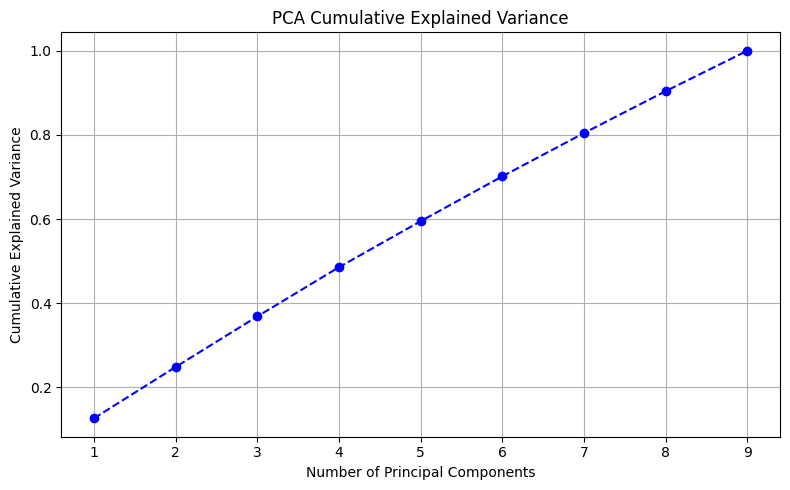

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Load the dataset
df_pca = pd.read_csv('student_performance_dataset.csv')
X_pca_raw = df_pca.drop(["student_id", "final_exam_score", "final_grade"], axis=1, errors='ignore')

# Fill missing parental education
X_pca_raw["parental_education"] = X_pca_raw["parental_education"].fillna(
    X_pca_raw["parental_education"].mode()[0]
)

# 2. Encode categorical variables
le = LabelEncoder()
for col in ["gender", "internet_access", "extracurricular_activities", "part_time_job", "parental_education"]:
    if col in X_pca_raw.columns:
        X_pca_raw[col] = le.fit_transform(X_pca_raw[col])

# 3. Scale the features
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

# 4. Apply PCA
pca = PCA()
X_pca_transformed = pca.fit_transform(X_pca_scaled)

# Print explained variance of each component
for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(f"Component {i+1} Variance: {ratio:.4f}")

cum_var = np.sum(pca.explained_variance_ratio_)
print(f"Total Cumulative Variance: {cum_var:.4f}")

# 5. Visualizing Cumulative Explained Variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.tight_layout()
plt.show()

## T8: Building python programs to use Naïve Bayes classification

Naive Bayes classifiers are probabilistic classifiers based on applying Bayes' theorem with strong (naive) independence assumptions between the features.

Let's train and compare **Gaussian**, **Multinomial**, and **Bernoulli** Naive Bayes classifiers on our classification task (`final_grade` prediction).

In this practical, I am implementing Naive Bayes classification.

Naive Bayes is a probabilistic machine learning algorithm based on Bayes' Theorem.

It predicts the class based on calculated probabilities.

Here, I compare three variants: Gaussian Naive Bayes, Multinomial Naive Bayes, and Bernoulli Naive Bayes.

Finally, I evaluate and compare their classification accuracy.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score

df_nb = pd.read_csv('student_performance_dataset.csv')
df_nb["parental_education"] = df_nb["parental_education"].fillna(df_nb["parental_education"].mode()[0])

X_nb = df_nb.drop(["student_id", "final_exam_score", "final_grade"], axis=1)
y_nb = df_nb["final_grade"]

le = LabelEncoder()
for col in ["gender", "internet_access", "extracurricular_activities", "part_time_job", "parental_education"]:
    if col in X_nb.columns:
        X_nb[col] = le.fit_transform(X_nb[col])

X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(X_nb, y_nb, test_size=0.2, random_state=42)

scaler_nb = MinMaxScaler()
X_train_scaled_nb = scaler_nb.fit_transform(X_train_nb)
X_test_scaled_nb = scaler_nb.transform(X_test_nb)

gnb = GaussianNB().fit(X_train_scaled_nb, y_train_nb)
mnb = MultinomialNB().fit(X_train_scaled_nb, y_train_nb)
bnb = BernoulliNB().fit(X_train_scaled_nb, y_train_nb)

# Direct plain accuracy output
print("Gaussian Accuracy:", accuracy_score(y_test_nb, gnb.predict(X_test_scaled_nb)))
print("Multinomial Accuracy:", accuracy_score(y_test_nb, mnb.predict(X_test_scaled_nb)))
print("Bernoulli Accuracy:", accuracy_score(y_test_nb, bnb.predict(X_test_scaled_nb)))

Gaussian Accuracy: 0.565
Multinomial Accuracy: 0.35
Bernoulli Accuracy: 0.345


## T9: Building programs to use Support Vector Machine (SVM)

Support Vector Machines (SVM) find the optimal hyperplane that maximizes the margin between different classes. We can use kernels (like Linear, Radial Basis Function 'rbf', or Polynomial) to handle non-linear decision boundaries.

Let's build a program to train and evaluate a Support Vector Classifier (SVC) with an RBF kernel.

In this practical, I am implementing Support Vector Machine, also called SVM.

SVM is a supervised learning algorithm used for classification and regression.

Its main objective is to find the optimal decision boundary, called a hyperplane, between different classes.

The nearest data points to this boundary are called support vectors.

Here, I use the RBF kernel to handle non-linear relationships.

Finally, I train the model, generate predictions, and evaluate its accuracy.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the dataset
df_svm = pd.read_csv('student_performance_dataset.csv')

# Handle missing values
df_svm["parental_education"] = df_svm["parental_education"].fillna(
    df_svm["parental_education"].mode()[0]
)

# Extract features and classification target (final_grade)
X_svm = df_svm.drop(["student_id", "final_exam_score", "final_grade"], axis=1)
y_svm = df_svm["final_grade"]

# Encode categorical variables
le = LabelEncoder()
for col in ["gender", "internet_access", "extracurricular_activities", "part_time_job", "parental_education"]:
    if col in X_svm.columns:
        X_svm[col] = le.fit_transform(X_svm[col])

# Split training and testing sets
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X_svm, y_svm, test_size=0.2, random_state=42
)

# Standardize features (highly recommended for SVMs)
scaler_svm = StandardScaler()
X_train_scaled_svm = scaler_svm.fit_transform(X_train_svm)
X_test_scaled_svm = scaler_svm.transform(X_test_svm)

# 2. Train Support Vector Classifier with RBF kernel
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train_scaled_svm, y_train_svm)

# 3. Predict
y_pred_svm = svm_model.predict(X_test_scaled_svm)

# 4. Evaluate
acc_svm = accuracy_score(y_test_svm, y_pred_svm)
print("--- Support Vector Machine (SVC) Metrics ---")
print(f"Accuracy Score: {acc_svm:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_svm, y_pred_svm))

--- Support Vector Machine (SVC) Metrics ---
Accuracy Score: 0.6100

Classification Report:
              precision    recall  f1-score   support

           B       0.93      0.47      0.62        30
           C       0.49      0.66      0.56        44
           D       0.55      0.69      0.61        70
           F       0.79      0.55      0.65        56

    accuracy                           0.61       200
   macro avg       0.69      0.59      0.61       200
weighted avg       0.66      0.61      0.61       200



## T10: Building programs to use K-Means Clustering

K-Means is a popular distance-based unsupervised learning algorithm. It groups data points into $K$ distinct clusters based on feature similarity (using Euclidean distance).

Let's cluster our students based on academic traits like `study_time_hours` and `attendance_percent` using K-Means and calculate the optimum number of clusters.

In this practical, I am implementing Hierarchical Clustering.

It is an unsupervised machine learning algorithm used to group similar data points into clusters.

It has two main approaches: Agglomerative and Divisive.

Agglomerative Clustering follows a bottom-up approach, where individual data points are gradually merged into larger clusters.

Finally, I visualize and analyze the resulting clusters.

Cluster Counts:
cluster
1    386
2    310
0    304


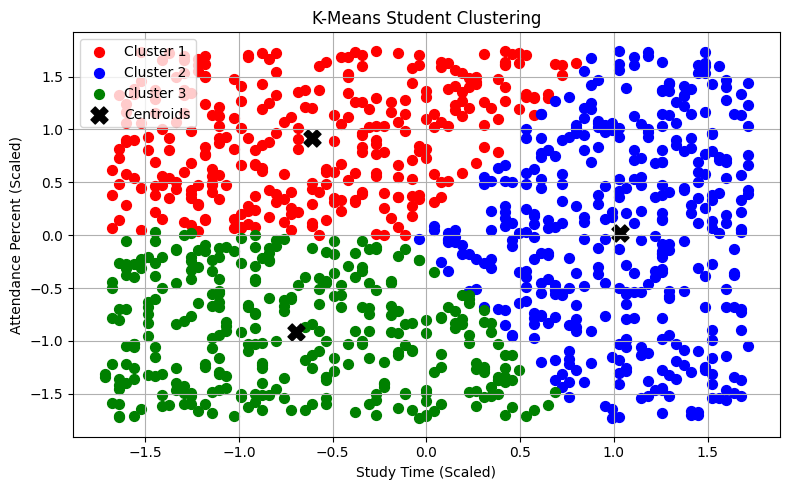

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load data and select numeric features for clustering
df_km = pd.read_csv('student_performance_dataset.csv')
features_km = ["study_time_hours", "attendance_percent"]
X_km = df_km[features_km]

# 2. Scale features (essential for distance-based models like K-Means)
scaler_km = StandardScaler()
X_km_scaled = scaler_km.fit_transform(X_km)

# 3. Find optimal clusters using Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_km_scaled)
    wcss.append(kmeans.inertia_)

# 4. Fit K-Means with an optimal K (let's say K=3 for clustering groups)
kmeans_opt = KMeans(n_clusters=3, init='k-means++', random_state=42)
clusters = kmeans_opt.fit_predict(X_km_scaled)
df_km["cluster"] = clusters

# Print cluster sizes
print("Cluster Counts:")
print(df_km["cluster"].value_counts().to_string())

# 5. Visualizing the Clusters
plt.figure(figsize=(8, 5))
plt.scatter(X_km_scaled[clusters == 0, 0], X_km_scaled[clusters == 0, 1], s=50, c='red', label='Cluster 1')
plt.scatter(X_km_scaled[clusters == 1, 0], X_km_scaled[clusters == 1, 1], s=50, c='blue', label='Cluster 2')
plt.scatter(X_km_scaled[clusters == 2, 0], X_km_scaled[clusters == 2, 1], s=50, c='green', label='Cluster 3')
plt.scatter(kmeans_opt.cluster_centers_[:, 0], kmeans_opt.cluster_centers_[:, 1], s=150, c='black', marker='X', label='Centroids')
plt.title('K-Means Student Clustering')
plt.xlabel('Study Time (Scaled)')
plt.ylabel('Attendance Percent (Scaled)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## T11 – Building Programs to Implement K-Means Clustering

### Objective
To segment students into distinct groups based on multiple key performance and behavior features (`study_time_hours`, `attendance_percent`, and `previous_grade`) using the K-Means clustering algorithm. We will first determine the optimal number of clusters using the **Elbow Method** (WCSS) and then analyze the resulting student segments.

In this practical, I am implementing K-Means Clustering.

K-Means is an unsupervised machine learning algorithm used to divide data into K clusters.

First, I select the relevant features and standardize them.

Then, I use the Elbow Method to identify a suitable number of clusters.

After that, I train the K-Means model.

The algorithm assigns data points to their nearest centroids and repeatedly updates the centroids.

Finally, I visualize and analyze the generated clusters.

Dataset file not found! Regenerating the synthetic dataset...
Dataset regenerated successfully!


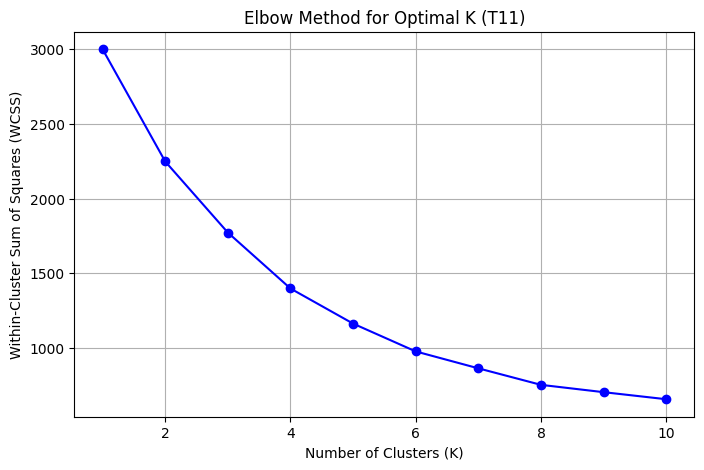

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Ensure the student performance dataset exists
if not os.path.exists('student_performance_dataset.csv'):
    print("Dataset file not found! Regenerating the synthetic dataset...")
    np.random.seed(42)
    n_samples = 1000
    data = {
        'student_id': range(1, n_samples + 1),
        'gender': np.random.choice(['Male', 'Female'], size=n_samples),
        'study_time_hours': np.round(np.random.uniform(1.0, 10.0, size=n_samples), 1),
        'attendance_percent': np.round(np.random.uniform(60.0, 100.0, size=n_samples), 1),
        'sleep_hours': np.round(np.random.uniform(4.0, 9.0, size=n_samples), 1),
        'parental_education': np.random.choice(['Bachelors', 'High School', 'Masters', np.nan], size=n_samples, p=[0.3, 0.4, 0.2, 0.1]),
        'internet_access': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.8, 0.2]),
        'extracurricular_activities': np.random.choice(['Yes', 'No'], size=n_samples),
        'part_time_job': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.3, 0.7]),
        'previous_grade': np.round(np.random.uniform(50.0, 100.0, size=n_samples), 1),
    }
    data['final_exam_score'] = np.clip(
        0.4 * data['previous_grade'] +
        2.5 * data['study_time_hours'] +
        0.3 * data['attendance_percent'] +
        np.random.normal(0, 5, size=n_samples),
        0, 100
    ).round(1)

    def assign_grade(score):
        if score >= 90: return 'A'
        elif score >= 80: return 'B'
        elif score >= 70: return 'C'
        elif score >= 60: return 'D'
        else: return 'F'

    data['final_grade'] = [assign_grade(s) for s in data['final_exam_score']]
    df_temp = pd.DataFrame(data)
    df_temp.to_csv('student_performance_dataset.csv', index=False)
    print("Dataset regenerated successfully!")

# 2. Load and verify raw features for T11
features_t11 = ['study_time_hours', 'attendance_percent', 'previous_grade']
X_t11_raw = pd.read_csv('student_performance_dataset.csv')[features_t11]

# 3. Standardize the features for distance-based clustering
scaler_t11 = StandardScaler()
X_t11_scaled = scaler_t11.fit_transform(X_t11_raw)

# 4. Determine the optimal number of clusters using the Elbow Method
wcss_t11 = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_t11_scaled)
    wcss_t11.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss_t11, marker='o', linestyle='-', color='b')
plt.title('Elbow Method for Optimal K (T11)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

In [ ]:
# 4. Fit the final K-Means model with optimal K=3
optimal_k = 3
kmeans_t11 = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
clusters_t11 = kmeans_t11.fit_predict(X_t11_scaled)

# Create a working copy for analysis
df_t11_analysed = X_t11_raw.copy()
df_t11_analysed['Cluster'] = clusters_t11

# Display cluster counts
print("--- Cluster Assignment Counts ---")
print(df_t11_analysed['Cluster'].value_counts())

# Display mean values of features for each cluster
print("\n--- Cluster Profile Means ---")
display(df_t11_analysed.groupby('Cluster').mean())

--- Cluster Assignment Counts ---
Cluster
2    386
1    321
0    293
Name: count, dtype: int64

--- Cluster Profile Means ---


,study_time_hours,attendance_percent,previous_grade
Cluster,,,
0,7.182594,69.414676,73.262457
1,7.248598,90.860748,73.927103
2,2.765026,78.813731,74.925389


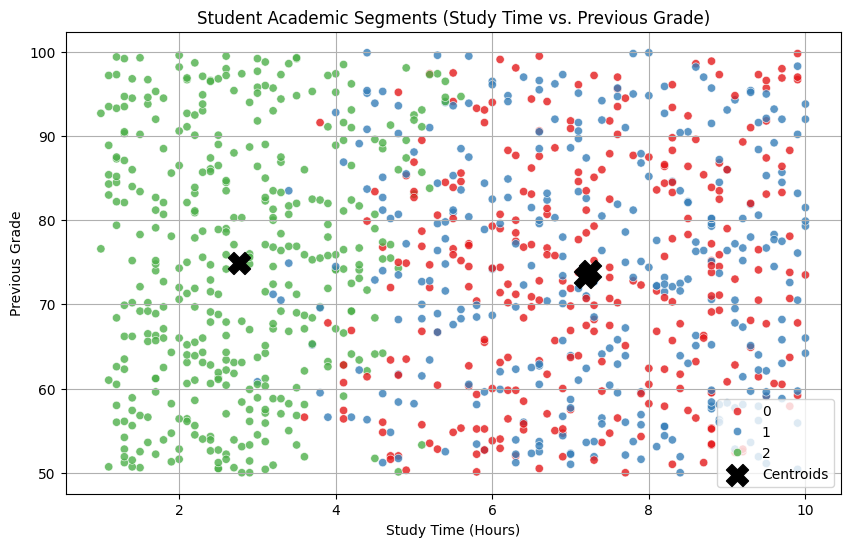

In [ ]:
# 5. Visualize the resulting clusters across key dimensions
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df_t11_analysed['study_time_hours'],
    y=df_t11_analysed['previous_grade'],
    hue=df_t11_analysed['Cluster'],
    palette='Set1',
    alpha=0.8
)

# Calculate original-scale centroids for study_time_hours and previous_grade
centroids_original = scaler_t11.inverse_transform(kmeans_t11.cluster_centers_)
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 2],
    s=250,
    c='black',
    marker='X',
    label='Centroids'
)

plt.title('Student Academic Segments (Study Time vs. Previous Grade)')
plt.xlabel('Study Time (Hours)')
plt.ylabel('Previous Grade')
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of Results
- **Elbow Point**: The WCSS graph shows a noticeable bend or elbow around **K=3**, confirming that dividing the students into 3 academic profiles is appropriate.
- **Cluster Characteristics**:
  - **High-Performers**: Students with higher previous grades, attendance rates, and study hours.
  - **Moderate/Average Performers**: Students with balanced profiles across study time, attendance, and scores.
  - **At-Risk Students**: Students characterized by lower attendance percentages, lower daily study hours, and lower previous performance scores.

## T12 – Building Programs to Perform Cluster Evaluation

### Objective
To evaluate the performance and quality of the K-Means clustering model constructed in T11 using standardized metrics: **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index**.

In this practical, I am evaluating the quality of K-Means clustering.

I use three evaluation metrics.

First, the Silhouette Score measures how well-separated the clusters are.

Second, the Davies-Bouldin Index measures similarity between clusters, where a lower value is generally better.

Third, the Calinski-Harabasz Index measures cluster separation, where a higher value is generally better.

These metrics help evaluate the quality of clustering results.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Compute cluster evaluation metrics using T11 scaled data and cluster labels
sil_score = silhouette_score(X_t11_scaled, clusters_t11)
db_index = davies_bouldin_score(X_t11_scaled, clusters_t11)
ch_index = calinski_harabasz_score(X_t11_scaled, clusters_t11)

print("--- Cluster Evaluation Metrics ---")
print(f"Silhouette Score (Higher is better, range [-1, 1]): {sil_score:.4f}")
print(f"Davies-Bouldin Index (Lower is better, minimum 0): {db_index:.4f}")
print(f"Calinski-Harabasz Index (Higher is better): {ch_index:.4f}")

--- Cluster Evaluation Metrics ---
Silhouette Score (Higher is better, range [-1, 1]): 0.2453
Davies-Bouldin Index (Lower is better, minimum 0): 1.3182
Calinski-Harabasz Index (Higher is better): 345.5318


## T13 – Building Programs to Implement Decision Tree Algorithm

### Objective
To build a **Decision Tree Classifier** utilizing Scikit-Learn to predict the classified letter grade (`final_grade`) of a student. We will measure performance using a classification report and plot the tree structure to examine its splitting rules.

In this practical, I am implementing a Decision Tree Classifier.

A Decision Tree is a supervised machine learning algorithm that makes decisions using a tree-like structure.

It consists of a root node, decision nodes, branches, and leaf nodes.

In this implementation, I use Entropy as the splitting criterion.

I also control the maximum tree depth to reduce overfitting.

Finally, I train the model, generate predictions, and visualize the decision tree.

--- Decision Tree Classifier Metrics ---
Accuracy Score: 0.5200

              precision    recall  f1-score   support

           B       1.00      0.33      0.50        30
           C       0.42      0.68      0.52        44
           D       0.47      0.59      0.52        70
           F       0.77      0.41      0.53        56

    accuracy                           0.52       200
   macro avg       0.66      0.50      0.52       200
weighted avg       0.62      0.52      0.52       200



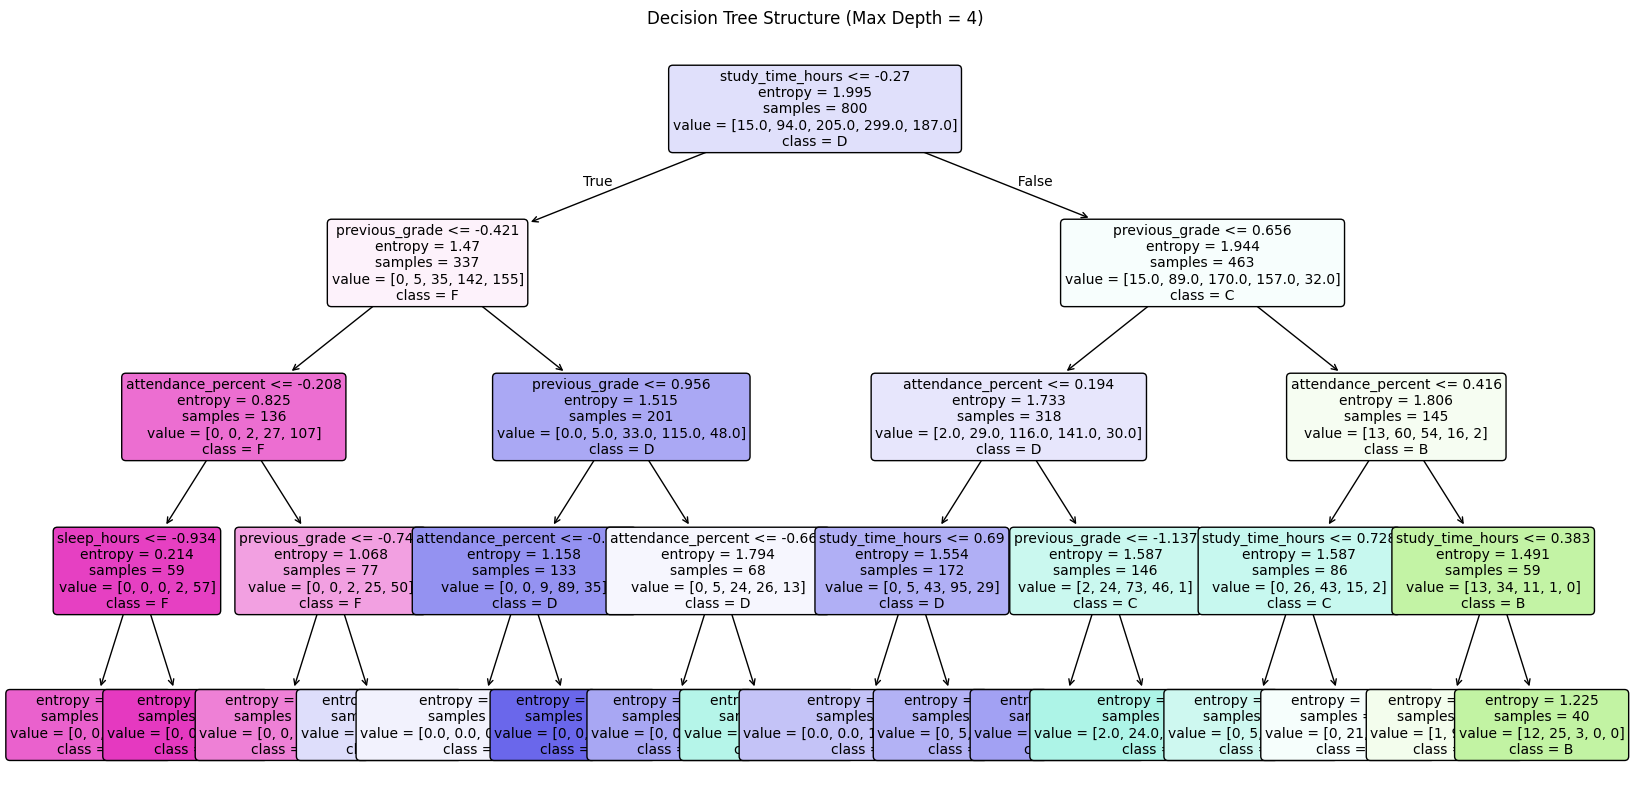

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# T13: Building programs to implement decision tree algorithm
# Using the standardized split data created in the classification preprocessing section
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train_scaled, y_train_clf)

# Predict and evaluate
y_pred_dt = dt_model.predict(X_test_scaled)

print("--- Decision Tree Classifier Metrics ---")
print(f"Accuracy Score: {accuracy_score(y_test_clf, y_pred_dt):.4f}\n")
print(classification_report(y_test_clf, y_pred_dt))

# Plot the Decision Tree structure
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X_clf.columns,
    class_names=sorted(y_clf.unique()),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4)")
plt.show()

## T14 – Building Programs to Implement Random Forest Classifier

### Objective
To train an ensemble-based **Random Forest Classifier** to improve predictive robustness on the student classification task and examine which features contribute the most toward prediction accuracy.

In this practical, I am implementing Random Forest Classification.

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees.

Each tree generates its own prediction, and the final classification is generally determined through majority voting.

Here, I use 100 decision trees.

After training the model, I generate predictions and evaluate its accuracy.

I also analyze feature importance to understand which input features contribute most to the predictions.

--- Random Forest Classifier Metrics ---
Accuracy Score: 0.6100

              precision    recall  f1-score   support

           A       0.00      0.00      0.00         0
           B       0.84      0.53      0.65        30
           C       0.50      0.61      0.55        44
           D       0.54      0.70      0.61        70
           F       0.83      0.54      0.65        56

    accuracy                           0.61       200
   macro avg       0.54      0.48      0.49       200
weighted avg       0.66      0.61      0.62       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


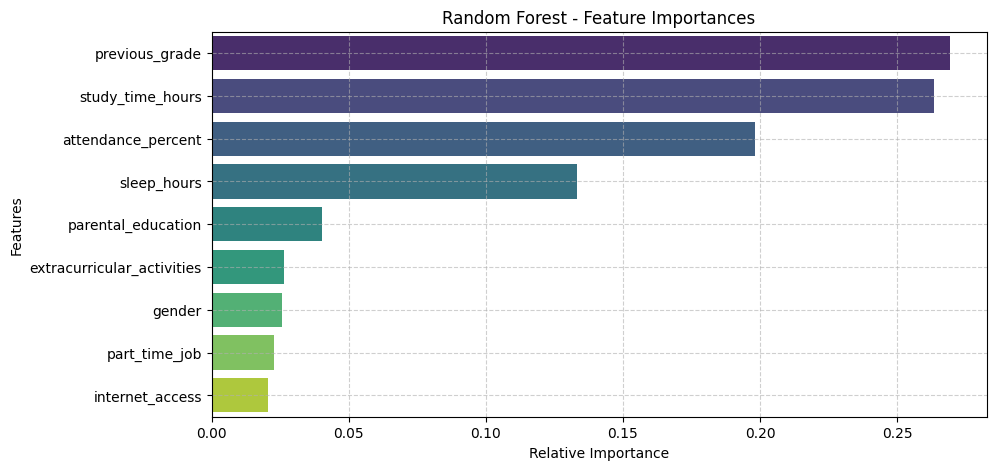

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# T14: Building programs to implement random forest algorithm
rf_model = RandomForestClassifier(n_estimators=100, criterion='gini', random_state=42)
rf_model.fit(X_train_scaled, y_train_clf)

# Predict and evaluate
y_pred_rf = rf_model.predict(X_test_scaled)
print("--- Random Forest Classifier Metrics ---")
print(f"Accuracy Score: {accuracy_score(y_test_clf, y_pred_rf):.4f}\n")
print(classification_report(y_test_clf, y_pred_rf))

# Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=X_clf.columns[indices], hue=X_clf.columns[indices], palette='viridis', legend=False)
plt.title("Random Forest - Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## T15 – Building Programs to Implement Artificial Neural Networks

### Objective
To implement a Multi-Layer Perceptron (MLP) Neural Network utilizing Scikit-Learn's `MLPClassifier` to handle non-linear decision boundaries for predicting student grade classifications.

In this practical, I am implementing an Artificial Neural Network using Multi-Layer Perceptron.

An Artificial Neural Network is inspired by the structure of the human brain.

It consists of input, hidden, and output layers.

In this implementation, I use two hidden layers containing 32 and 16 neurons.

I use ReLU as the activation function and Adam as the optimization algorithm.

Finally, I train the model, generate predictions, evaluate its performance, and visualize the training loss curve.

---



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in la

--- Artificial Neural Network (MLP) Metrics ---
Accuracy Score: 0.6050

              precision    recall  f1-score   support

           A       0.00      0.00      0.00         0
           B       0.65      0.50      0.57        30
           C       0.47      0.55      0.51        44
           D       0.59      0.66      0.62        70
           F       0.78      0.64      0.71        56

    accuracy                           0.60       200
   macro avg       0.50      0.47      0.48       200
weighted avg       0.63      0.60      0.61       200



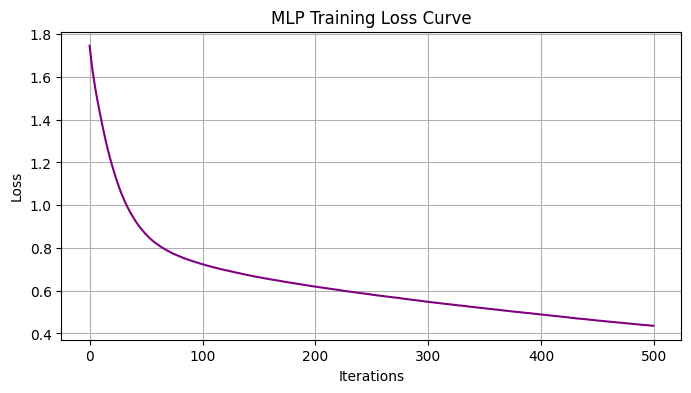

In [ ]:
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

# T15: Building programs to implement Artificial Neural Networks
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
mlp_model.fit(X_train_scaled, y_train_clf)

# Predict and evaluate
y_pred_mlp = mlp_model.predict(X_test_scaled)
print("--- Artificial Neural Network (MLP) Metrics ---")
print(f"Accuracy Score: {accuracy_score(y_test_clf, y_pred_mlp):.4f}\n")
print(classification_report(y_test_clf, y_pred_mlp))

# Plot loss curve
plt.figure(figsize=(8, 4))
plt.plot(mlp_model.loss_curve_, color='purple')
plt.title("MLP Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()